# Paper figures — design workspace

The CSV workflow follows `analyze.ipynb`; this notebook concentrates on **how the figures look at the final LNCS width of 122 mm**. Run all cells, then change the settings below to compare designs or environments. Requires NumPy, pandas, Matplotlib, and a Jupyter Python kernel.

**Included:** FND, simulation endpoint, FND + endpoint, alive-node curves, cumulative energy, round energy, FND/endpoint versus node count, four computation-runtime views, and ranked sensor-energy profiles. All code lives here; the simulator and original notebook are unchanged.

The default preview selects the newest paper campaign with published main results, otherwise it falls back to historical CSVs. Primary views cover **100 and 150 uniform nodes** as data becomes available; the node-count sweep uses clustered runs at the same volume. Main and short diagnostic runs are separate. New campaigns carry frozen sources, map hashes, parameters, seeds and termination reasons; historical filenames alone cannot verify these. More independent runs can stabilize a mean curve; extra smoothing does not create evidence or reduce true run-to-run variability.

Exports go to `output/figures/analyze2/`: vector PDF, PNG previews, caption/alt-text suggestions, and the selected-run manifest. EPS is an optional setting. Notebook images are embedded so the result is visible without rerunning.


In [1]:
from pathlib import Path
from io import BytesIO
import hashlib
import json
import re

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.colors import to_rgb
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator, StrMethodFormatter
from IPython.display import display, Markdown


def project_root():
    for folder in [Path.cwd(), *Path.cwd().parents]:
        if (folder / "src" / "analyze.ipynb").is_file() and (folder / "runs").is_dir():
            return folder
    raise FileNotFoundError("Open this notebook from the repository root or src/.")


ROOT = project_root()


## 1. Data filters

Keep the two selections separate: `ENVIRONMENTS` controls individual-scenario figures; `SWEEP_GROUPS` controls node-count figures. Use `None` for every available environment/group. Dates accept partial `YYYY-MM-DD-HH` values, as in the original notebook. No optimizer campaign is loaded implicitly.


In [2]:
# Prefer the newest campaign with published main results; never mix old runs
# with a new campaign or import the short diagnostics as lifetime experiments.
CAMPAIGNS = sorted((ROOT / "runs").glob("paper_*"), reverse=True)
READY_CAMPAIGNS = [p for p in CAMPAIGNS if (p / "campaign.json").is_file()
                   and any((p / "csv").glob("*.csv"))]
RUNS_DIR = READY_CAMPAIGNS[0] / "csv" if READY_CAMPAIGNS else ROOT / "runs"
START_DATETIME = "0000-00-00-00"
END_DATETIME = "9999-99-99-99"
SEEDS = None                  # Filename/deployment seeds; algorithm seeds are in new-run metadata
ALGORITHMS = ["SimpleACO", "NodeACO", "PSO", "AC-ACO", "D-ACO"]
PRIMARY_ENVIRONMENTS = ["500_500_500_100_uniform", "500_500_500_150_uniform"]
ENVIRONMENTS = [e for e in PRIMARY_ENVIRONMENTS if any(RUNS_DIR.glob(e + "_*.csv"))] or None
SWEEP_GROUPS = [(500, 500, 500, "clustered")]  # (width, height, depth, distribution)

T_MAX = 3500                  # Configured campaign horizon; CSVs do not store it
T_MAX_BY_ENV = {}             # Optional: {"500_500_500_100_uniform": 3500}
RUNTIME_WINDOW = 1000         # Same first K completed rounds for runtime bars / node sweep
RUNTIME_LOG_SCALE = True      # Full timeline retains timing spikes; logarithmic y-axis

AVG_WINDOW = 100              # Non-overlapping raw-data block means; no extra smoothing
ENERGY_UNIT = "J"
EXPORT = True
EXPORT_FORMATS = ("pdf", "png")  # Add "eps" if needed by the selected TeX workflow
OUTPUT_DIR = ROOT / "output" / "figures" / "analyze2"

if type(AVG_WINDOW) is not int or AVG_WINDOW < 1:
    raise ValueError("AVG_WINDOW must be a positive integer.")
if type(RUNTIME_WINDOW) is not int or RUNTIME_WINDOW < 1:
    raise ValueError("RUNTIME_WINDOW must be a positive integer.")


def horizon_for(environment):
    horizon = T_MAX_BY_ENV.get(environment, T_MAX)
    if horizon is not None and (type(horizon) is not int or horizon < 1):
        raise ValueError("T_MAX and per-environment overrides must be positive integers or None.")
    return horizon


## 2. Visual controls

- **Same algorithm, same appearance everywhere.** Colors also have distinct markers and line styles for grayscale printing.
- **Actual publication size.** The PDF canvas stays exactly 122 mm wide; no tight crop silently changes the physical width.
- Serif labels, a dashed grid, and a legend above the data. Scenario details live in the caption rather than an oversized chart title.
- Reference-inspired red/orange/blue/purple/green colors, filled markers, and a stronger solid green stroke for D-ACO. Solid bars have black error bars, with **mean ± sample SD written explicitly above them**. A single file shows “SD n/a”, not a fabricated zero SD.
- Curves retain a fixed set of runs for each algorithm, ending at its shortest selected run. They never extend beyond recorded service. Means and faint SD envelopes are descriptive across selected files.

Adjust `FONT_PT`, `FIG_WIDTH_MM`, `FIG_HEIGHT_MM`, `PALETTE`, `MARKERS`, `LINESTYLES`, or `SHOW_SD` here, then rerun the figure cells. Set `MONOCHROME = True` for the print check. Each figure also gets a notebook caption and a metadata record on disk.


In [3]:
FIG_WIDTH_MM = 122
FIG_HEIGHT_MM = 82
FONT_PT = 9.5
MONOCHROME = False
SHOW_SD = True
PREVIEW_DPI = 180
PNG_DPI = 300

PALETTE = {
    "SimpleACO": "#D62728", "NodeACO": "#FF9800", "PSO": "#1976D2",
    "AC-ACO": "#9C27B0", "D-ACO": "#2E7D32",
}
MARKERS = {"SimpleACO": "o", "NodeACO": "s", "PSO": "v", "AC-ACO": "p", "D-ACO": "D"}
LINESTYLES = {
    "SimpleACO": (0, (5, 2)), "NodeACO": (0, (3, 1.5, 1, 1.5)),
    "PSO": (0, (1, 1.7)), "AC-ACO": (0, (5, 2)), "D-ACO": "-",
}
HATCHES = {"SimpleACO": "//", "NodeACO": "\\", "PSO": "..", "AC-ACO": "xx", "D-ACO": ""}
FONT_FAMILY = next((name for name in ["Times New Roman", "Liberation Serif", "DejaVu Serif"]
                    if any(f.name == name for f in font_manager.fontManager.ttflist)), "DejaVu Serif")

mpl.rcParams.update({
    "font.family": "serif", "font.serif": [FONT_FAMILY], "font.size": FONT_PT,
    "axes.labelsize": FONT_PT + 0.5, "axes.titlesize": FONT_PT,
    "xtick.labelsize": FONT_PT - 1, "ytick.labelsize": FONT_PT - 1,
    "legend.fontsize": 7.9, "axes.linewidth": 0.8,
    "axes.edgecolor": "#42484D", "text.color": "#22282D",
    "axes.labelcolor": "#22282D", "xtick.color": "#42484D", "ytick.color": "#42484D",
    "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.major.size": 3, "ytick.major.size": 3,
    "lines.linewidth": 1.25, "lines.markersize": 3.8,
    "legend.frameon": False, "legend.handlelength": 2.3,
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "figure.dpi": PREVIEW_DPI, "savefig.dpi": PNG_DPI,
    "pdf.fonttype": 42, "ps.fonttype": 42, "svg.fonttype": "none", "mathtext.fontset": "stix",
    "hatch.linewidth": 0.45, "axes.unicode_minus": False,
})


def color(algo):
    return "#333333" if MONOCHROME else PALETTE.get(algo, "#596773")


def pale(algo):
    return tuple(0.90 + 0.10 * v for v in to_rgb(color(algo)))


def statistic_label(values, decimals=0):
    mean = float(np.mean(values))
    label = f"{mean:,.{decimals}f}"
    return label + (f"\n±{np.std(values, ddof=1):,.{decimals}f}" if len(values) > 1 else "\nSD n/a")


def line_style(algo):
    return dict(color=color(algo), marker=MARKERS.get(algo, "o"),
                linestyle=LINESTYLES.get(algo, "-"), linewidth=2.0 if algo == "D-ACO" else 1.6,
                markersize=4.7 if algo == "D-ACO" else 4.1,
                markerfacecolor=color(algo), markeredgewidth=0.6,
                zorder=5 if algo == "D-ACO" else 3)


def canvas(height_mm=FIG_HEIGHT_MM):
    fig = plt.figure(figsize=(FIG_WIDTH_MM / 25.4, height_mm / 25.4))
    ax = fig.add_axes([0.16, 0.18, 0.81, 0.64])
    clean_axis(ax)
    return fig, ax


def clean_axis(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_axisbelow(True)
    ax.grid(axis="both", color="#D9DDE0", linewidth=0.6, linestyle="--")
    ax.yaxis.set_major_locator(MaxNLocator(nbins=5, min_n_ticks=3))
    ax.tick_params(direction="out", pad=3)


def legend_above(fig, algos):
    handles = [Line2D([], [], label=a, **line_style(a)) for a in algos]
    fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.55, 0.955),
               ncol=min(5, max(1, len(handles))), columnspacing=1.0,
               handletextpad=0.45, handlelength=2.0, labelspacing=0.5)


def short_note(fig, text):
    fig.text(0.56, 0.025, text, ha="center", va="bottom", fontsize=7.2, color="#59636B")


def horizon_line(ax, horizon, axis="x"):
    # Reference only: never pad observations to the configured simulation limit.
    if horizon is None:
        return
    style = dict(color="#5C6368", linewidth=0.8, linestyle=(0, (5, 3)), zorder=2)
    label = rf"$T_{{\max}} = {horizon}$"
    if axis == "x":
        ax.axvline(horizon, **style)
        ax.set_xlim(0, max(ax.get_xlim()[1], horizon * 1.025))
        ax.text(horizon, 1.025, label, transform=ax.get_xaxis_transform(),
                ha="right", va="bottom", fontsize=7.4, color="#59636B")
    else:
        ax.axhline(horizon, **style)
        ax.set_ylim(0, max(ax.get_ylim()[1], horizon * 1.20))
        ax.text(0, 1.025, label + " (dashed)", transform=ax.transAxes, ha="left", va="bottom",
                fontsize=7.4, color="#59636B")


def horizon_caption(environment):
    h = horizon_for(environment)
    return (f"The dashed reference marks the configured simulation limit T_max = {h:,} rounds; "
            "curves are not extended to that limit. " if h is not None else "No campaign horizon was specified. ")


FIGURES = {}
FIGURE_METADATA = {}


def finish(fig, key, caption, alt, note=None):
    if note:
        short_note(fig, note)
    fig.canvas.draw()
    if EXPORT:
        OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
        for fmt in EXPORT_FORMATS:
            fig.savefig(OUTPUT_DIR / f"{key}.{fmt}", format=fmt, dpi=PNG_DPI)
    FIGURES[key] = fig
    FIGURE_METADATA[key] = dict(caption=caption, description=alt)
    display(Markdown(f"**{key}** — {caption}"))
    display(fig)
    plt.close(fig)
    return fig


print(f"Design: {FIG_WIDTH_MM} × {FIG_HEIGHT_MM} mm; {FONT_FAMILY}, {FONT_PT:g} pt.")


Design: 122 × 82 mm; Times New Roman, 9.5 pt.


## 3. Load and validate runs

Rounds are shown as **1, 2, …**, corresponding to CSV `round + 1`. FND is the first record below N alive. **Simulation endpoint / service duration** is `R_end = len(history)`: the number of completed service rounds before stopping or reaching the configured horizon. It is observed even if nodes remain alive; an empty file has zero completed service rounds but no FND. This metric replaces LND in the figure selection.

Set `T_MAX` from the campaign configuration, with overrides in `T_MAX_BY_ENV` if necessary; it is **not inferred from run length**. Set it to `None` if the historical horizon is unknown. A run with `R_end = T_max` reached the configured limit; a shorter run ended below that limit. Historical CSVs cannot establish an early-stop cause; new campaign sidecars provide `termination_reason`. A capped run's operational duration beyond the horizon remains unobserved.

`time` stores elapsed **wall-clock computation seconds per completed round**, including search, evaluation, energy update, and first-round calibration. It is not acoustic propagation delay or CPU time. Its cumulative sum excludes any unrecorded final failed search, CSV output, and time between rounds. Runtime bars and node-count comparisons use the same first `RUNTIME_WINDOW` rounds, including initialization. Full timelines retain all valid timing samples; large spikes are reported, not silently removed.


In [4]:
NAME_PATTERN = re.compile(
    r"^(?P<w>\d+)_(?P<h>\d+)_(?P<d>\d+)_(?P<n>\d+)_"
    r"(?P<distribution>.+)_(?P<timestamp>\d{10})_(?P<seed>\d+)_(?P<algo>.+)$"
)


def date_bound(value, end=False):
    digits = value.replace("-", "")
    if not digits.isdigit() or len(digits) > 10:
        raise ValueError("Use a partial YYYY-MM-DD-HH date or its digits.")
    return digits.ljust(10, "9" if end else "0")


def load_runs():
    found, skipped = [], []
    start, end = date_bound(START_DATETIME), date_bound(END_DATETIME, True)
    if start > end:
        raise ValueError("START_DATETIME is later than END_DATETIME.")
    for path in sorted(Path(RUNS_DIR).glob("*.csv")):
        if path.name.endswith("_sensor-energy.csv"):
            continue
        match = NAME_PATTERN.fullmatch(path.stem)
        if match is None:
            skipped.append((path.name, "unrecognized benchmark filename"))
            continue
        meta = match.groupdict()
        algo, stamp, seed = meta["algo"], meta["timestamp"], int(meta["seed"])
        if algo not in ALGORITHMS or not start <= stamp <= end or (SEEDS is not None and seed not in SEEDS):
            continue
        w, h, d, n = (int(meta[k]) for k in ["w", "h", "d", "n"])
        if n <= 0:
            raise ValueError(f"{path.name}: sensor count must be positive.")
        history = pd.read_csv(path)
        required = ["round", "alive_nodes", "round_energy"]
        if not set(required) <= set(history.columns):
            raise ValueError(f"{path.name}: missing {set(required) - set(history.columns)}")
        history[required] = history[required].apply(pd.to_numeric, errors="raise")
        if not history.empty:
            if not np.isfinite(history[required].to_numpy()).all():
                raise ValueError(f"{path.name}: nonfinite values in required columns.")
            if not np.array_equal(history["round"].to_numpy(), np.arange(len(history))):
                raise ValueError(f"{path.name}: rounds must be contiguous and start at zero.")
            alive = history["alive_nodes"].to_numpy()
            if ((alive < 0) | (alive > n) | (alive != np.floor(alive))).any() or (np.diff(alive) > 0).any():
                raise ValueError(f"{path.name}: invalid alive-node trajectory.")
            if (history["round_energy"] < 0).any():
                raise ValueError(f"{path.name}: negative energy demand.")
        if "time" in history:
            history["time"] = pd.to_numeric(history["time"], errors="raise")
            finite_times = history["time"].dropna().to_numpy(dtype=float)
            if not np.isfinite(finite_times).all() or (finite_times < 0).any():
                raise ValueError(f"{path.name}: invalid round runtime.")
        environment = f"{w}_{h}_{d}_{n}_{meta['distribution']}"
        horizon = horizon_for(environment)
        if horizon is not None and len(history) > horizon:
            raise ValueError(f"{path.name}: more completed rounds than configured T_MAX; update the horizon/filter.")
        history = history.assign(paper_round=history["round"].astype(int) + 1)
        metadata_path = path.with_suffix(".meta.json")
        metadata = json.loads(metadata_path.read_text(encoding="utf-8")) if metadata_path.is_file() else {}
        if metadata and metadata.get("phase") != "main":
            raise ValueError(f"{path.name}: diagnostic data must not be mixed into the main-paper cohort.")
        if metadata and metadata.get("horizon") != horizon_for(environment):
            raise ValueError(f"{path.name}: metadata horizon differs from T_MAX; set the correct override.")
        found.append(dict(environment=environment,
                          group=(w, h, d, meta["distribution"]), sensor_count=n,
                          algo=algo, seed=seed, timestamp=stamp, path=path, history=history, metadata=metadata))
    if not found:
        raise ValueError("No benchmark runs match the filters.")
    if skipped:
        display(pd.DataFrame(skipped, columns=["file", "skip reason"]))
    return found


def summarize(run):
    h, n = run["history"], run["sensor_count"]
    horizon = horizon_for(run["environment"])
    timing_complete = "time" in h and len(h) > 0 and h["time"].notna().all()
    window_ok = timing_complete and len(h) >= RUNTIME_WINDOW
    def event(mask):
        hits = h.loc[mask, "paper_round"]
        return float(hits.iloc[0]) if len(hits) else np.nan
    return dict(environment=run["environment"], group=run["group"], algo=run["algo"],
                seed=run["seed"], timestamp=run["timestamp"], sensor_count=n,
                completed_rounds=len(h), endpoint=int(h["paper_round"].iloc[-1]) if len(h) else np.nan,
                T_max=horizon, endpoint_status=("zero completed rounds" if h.empty else
                    "horizon unspecified" if horizon is None else
                    "at configured horizon" if len(h) == horizon else "below configured horizon"),
                timing_complete=timing_complete,
                recorded_compute_s=float(h["time"].sum()) if timing_complete else np.nan,
                runtime_K_ms=float(h["time"].iloc[:RUNTIME_WINDOW].mean()*1000) if window_ok else np.nan,
                max_round_time_s=float(h["time"].max()) if timing_complete else np.nan,
                final_alive=int(h["alive_nodes"].iloc[-1]) if len(h) else np.nan,
                termination_reason=run["metadata"].get("termination_reason", "not recorded"),
                FND=event(h["alive_nodes"] < n), HND=event(h["alive_nodes"] <= n // 2),
                empty=h.empty, file=run["path"].name)


def environment_label(environment):
    w, h, d, n, distribution = environment.split("_", 4)
    return f"{w} × {h} × {d} m; {n} sensors; {distribution} deployment"


def algo_order(items):
    present = set(items)
    return [a for a in ALGORITHMS if a in present]


runs = load_runs()
summary = pd.DataFrame([summarize(run) for run in runs])
RUNS_BY_ENV = {}
for run in runs:
    RUNS_BY_ENV.setdefault(run["environment"], []).append(run)
selected_envs = (sorted(env for env, cohort in RUNS_BY_ENV.items()
                        if any(not r["history"].empty for r in cohort))
                 if ENVIRONMENTS is None else list(ENVIRONMENTS))
missing = set(selected_envs) - set(RUNS_BY_ENV)
if missing:
    raise ValueError(f"Requested environments have no matching files: {sorted(missing)}")

display(summary.groupby(["environment", "algo"], sort=False).agg(
    files=("file", "size"), nonempty=("empty", lambda s: int((~s).sum())),
    fnd_observed=("FND", "count"), mean_service_rounds=("completed_rounds", "mean"),
    at_configured_horizon=("endpoint_status", lambda s: int(s.eq("at configured horizon").sum())),
    runtime_window_files=("runtime_K_ms", "count")))
print(f"Loaded {len(runs)} run files; {int(summary['empty'].sum())} contain no completed rounds.")
print("Historical filenames do not verify map/code/parameter equivalence; previews are descriptive."
      if any(not r["metadata"] for r in runs) else
      "Campaign sidecars provide map hashes, parameters, algorithm seeds, and termination reasons.")


Loaded 73 run files; 15 contain no completed rounds.
Historical filenames do not verify map/code/parameter equivalence; previews are descriptive.


files  ...  runtime_window_files
environment               algo              ...                      
300_300_300_100_clustered AC-ACO         2  ...                     2
                          D-ACO          2  ...                     2
                          NodeACO        2  ...                     2
                          PSO            2  ...                     2
                          SimpleACO      2  ...                     2
300_300_300_200_clustered AC-ACO         1  ...                     1
                          D-ACO          2  ...                     2
                          NodeACO        1  ...                     1
                          PSO            2  ...                     2
                          SimpleACO      2  ...                     2
300_300_300_50_clustered  AC-ACO         2  ...                     2
                          D-ACO          2  ...                     2
                          NodeACO        2  ...                     2
                          PSO            2  ...                     2
                          SimpleACO      2  ...                     2
500_500_500_100_clustered AC-ACO         1  ...                     1
                          D-ACO          1  ...                     1
                          NodeACO        1  ...                     1
                          PSO            1  ...                     1
                          SimpleACO      1  ...                     1
500_500_500_100_normal    AC-ACO         1  ...                     1
                          D-ACO          1  ...                     1
                          NodeACO        1  ...                     1
                          PSO            1  ...                     1
                          SimpleACO      1  ...                     1
500_500_500_100_uniform   AC-ACO         2  ...                     2
                          D-ACO          2  ...                     2
                          NodeACO        2  ...                     2
                          PSO            2  ...                     2
                          SimpleACO      2  ...                     2
500_500_500_200_clustered AC-ACO         1  ...                     1
                          D-ACO          1  ...                     1
                          NodeACO        1  ...                     1
                          PSO            1  ...                     1
                          SimpleACO      1  ...                     1
500_500_500_50_clustered  AC-ACO         1  ...                     1
                          D-ACO          1  ...                     1
                          NodeACO        1  ...                     1
                          PSO            1  ...                     1
                          SimpleACO      1  ...                     1
800_800_800_100_clustered AC-ACO         1  ...                     0
                          D-ACO          1  ...                     0
                          NodeACO        1  ...                     0
                          PSO            1  ...                     0
                          SimpleACO      1  ...                     0
800_800_800_200_clustered AC-ACO         1  ...                     0
                          D-ACO          1  ...                     0
                          NodeACO        1  ...                     0
                          PSO            1  ...                     0
                          SimpleACO      1  ...                     0
800_800_800_50_clustered  AC-ACO         1  ...                     0
                          D-ACO          1  ...                     0
                          NodeACO        1  ...                     0
                          PSO            1  ...                     0
                          SimpleACO      1  ...                     0

[55 rows x 6 columns]

## 4. Stability and simulation endpoint — three alternatives

Choose **FND alone**, **simulation endpoint alone**, or **FND + endpoint**. Pale bars show means, whiskers show sample SD when n > 1, and dots show individual files. For FND groups with unobserved events, open upward triangles mark the last recorded rounds instead of invented death events. Endpoint bars include zero-round runs; square markers denote files that reach the configured `T_max`. These are capped observations, not evidence that the algorithm would stop there without the cap. The combined figure shares one y-axis scale and a dashed horizon reference.


**500_500_500_100_uniform_fnd** — fnd comparison: 500 × 500 × 500 m; 100 sensors; uniform deployment. Bars: mean; whiskers: sample SD; dots: selected files. Open triangles mark FND not observed by the recorded endpoint. The dashed reference marks the configured simulation limit T_max = 3,500 rounds; curves are not extended to that limit. 

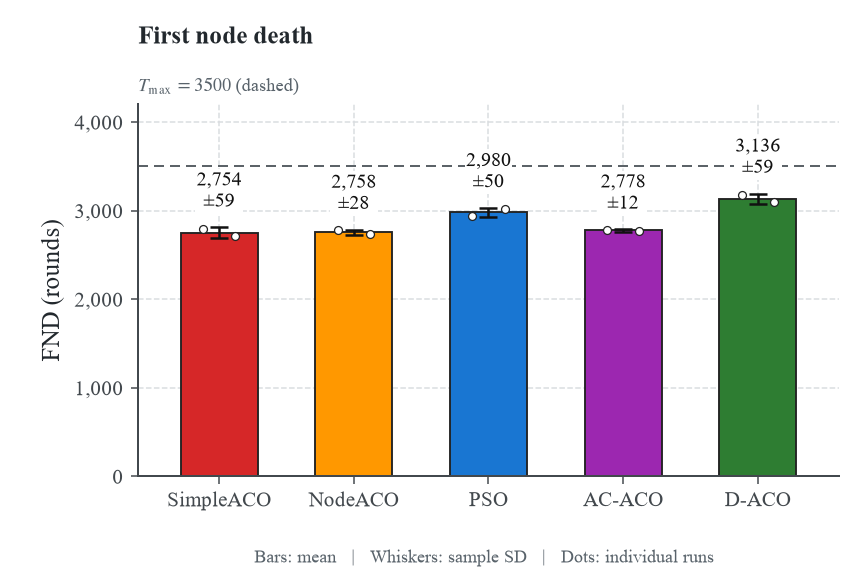

**500_500_500_100_uniform_service_rounds** — service rounds comparison: 500 × 500 × 500 m; 100 sensors; uniform deployment. Bars: mean; whiskers: sample SD; dots: selected files. Service duration R_end counts completed rounds, even if nodes remain alive; squares indicate the configured horizon was reached. Early-stop causes are available only where per-run metadata exists. The dashed reference marks the configured simulation limit T_max = 3,500 rounds; curves are not extended to that limit. 

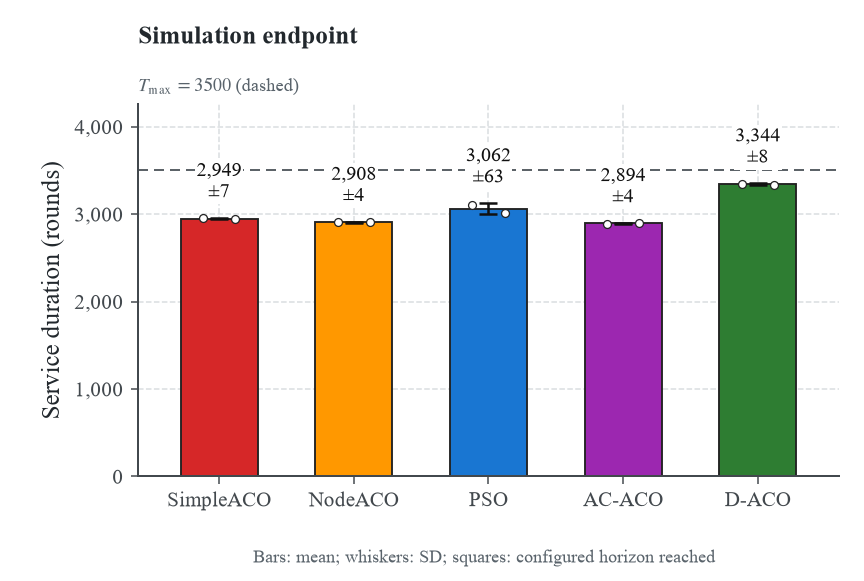

**500_500_500_100_uniform_fnd_service** — Stability and endpoint on a common scale: 500 × 500 × 500 m; 100 sensors; uniform deployment. (a) First node death. (b) Simulation endpoint R_end, the number of completed service rounds. Triangle: FND unobserved; square: configured horizon reached. The dashed reference marks the configured simulation limit T_max = 3,500 rounds; curves are not extended to that limit. 

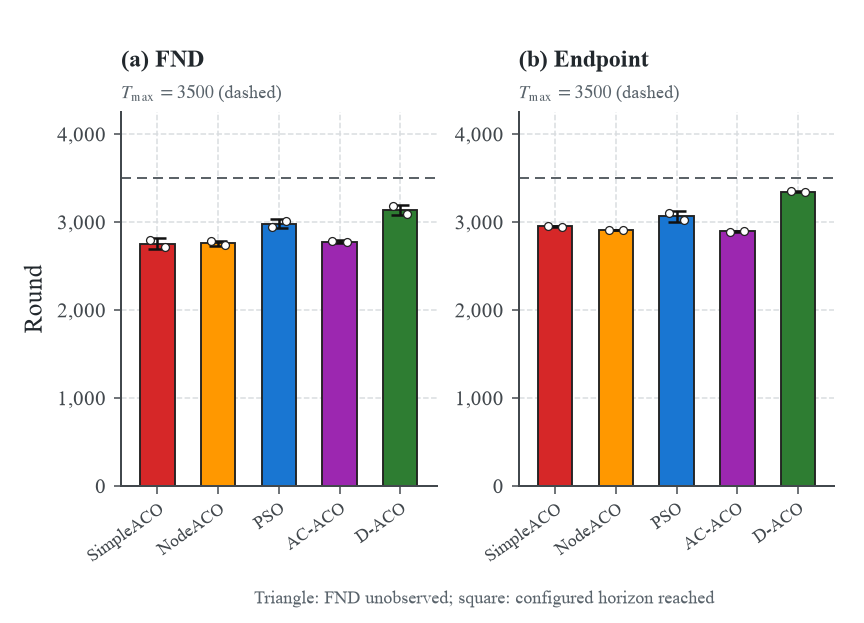

In [5]:
def lifetime_axis(ax, frame, metric, label_values=True):
    algos = algo_order(frame["algo"])
    y_values = []
    for x, algo in enumerate(algos):
        group = frame.loc[frame["algo"] == algo]
        valid = group if metric == "completed_rounds" else group.loc[~group["empty"]]
        values = valid[metric].dropna().to_numpy(dtype=float)
        ends = valid.loc[valid[metric].isna(), "endpoint"].to_numpy(dtype=float)
        y_values.extend(values)
        y_values.extend(ends)
        if len(values) == len(group) and len(values):
            mean = float(values.mean())
            sd = float(values.std(ddof=1)) if len(values) > 1 else 0.0
            ax.bar(x, mean, width=0.57, color=color(algo), edgecolor="#222222", linewidth=0.75,
                   hatch=HATCHES.get(algo, "") if MONOCHROME else None, zorder=2)
            if len(values) > 1:
                ax.errorbar(x, mean, yerr=sd, fmt="none", color="#111111", capsize=3.5,
                            elinewidth=1.0, capthick=1.0, zorder=4)
            offsets = np.linspace(-0.12, 0.12, len(values)) if len(values) > 1 else np.zeros(1)
            ax.scatter(x + offsets, values, s=10, facecolors="white", edgecolors="#222222",
                       linewidths=0.5, zorder=5)
            if metric == "completed_rounds":
                capped = valid["endpoint_status"].eq("at configured horizon").to_numpy()
                ax.scatter((x+offsets)[capped], values[capped], marker="s", s=23,
                           facecolors="white", edgecolors=color(algo), linewidths=0.85, zorder=6)
            if label_values:
                ax.annotate(statistic_label(values), (x, max(values.max(), mean+sd)), xytext=(0, 6),
                            textcoords="offset points", ha="center", va="bottom", fontsize=8, color="#111111",
                            bbox=dict(facecolor="white", edgecolor="none", pad=0.6))
        else:
            for rows, observed in [(valid.loc[valid[metric].notna()], True),
                                   (valid.loc[valid[metric].isna()], False)]:
                if rows.empty:
                    continue
                offsets = np.linspace(-0.13, 0.13, len(rows)) if len(rows) > 1 else np.zeros(1)
                ys = rows[metric if observed else "endpoint"].to_numpy(dtype=float)
                ax.scatter(x + offsets, ys, marker=MARKERS[algo] if observed else "^", s=29,
                           facecolors=color(algo) if observed else "white", edgecolors=color(algo),
                           linewidths=1, zorder=5)
            if label_values and len(valid):
                top = max([*values, *ends])
                ax.annotate(f"{len(values)}/{len(group)} observed", (x, top), xytext=(0, 8),
                            textcoords="offset points", ha="center", fontsize=6.6, color="#59636B")
            elif not len(valid):
                ax.text(x, 0.07, "No rounds", transform=ax.get_xaxis_transform(),
                        ha="center", fontsize=7, rotation=90, color="#59636B")
    ax.set_xticks(range(len(algos)), algos)
    ax.set_xlim(-0.6, len(algos)-0.4)
    ax.set_ylim(0, max(1, max(y_values, default=1)) * 1.27)
    ax.set_ylabel("Service duration (rounds)" if metric == "completed_rounds" else f"{metric} (rounds)")
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    return algos


for env in selected_envs:
    frame = summary.loc[summary["environment"] == env]
    scenario = environment_label(env)
    for metric in ["FND", "completed_rounds"]:
        fig, ax = canvas()
        lifetime_axis(ax, frame, metric)
        horizon_line(ax, horizon_for(env), axis="y")
        # This chart has algorithm labels on the x-axis, so no redundant algorithm legend.
        fig.text(0.16, 0.925, "First node death" if metric == "FND" else "Simulation endpoint",
                 fontsize=10, fontweight="bold")
        key = "fnd" if metric == "FND" else "service_rounds"
        meaning = ("Open triangles mark FND not observed by the recorded endpoint. " if metric == "FND" else
                   "Service duration R_end counts completed rounds, even if nodes remain alive; squares indicate the configured horizon was reached. "
                   "Early-stop causes are available only where per-run metadata exists. ")
        finish(fig, f"{env}_{key}", f"{key.replace('_', ' ')} comparison: {scenario}. "
               "Bars: mean; whiskers: sample SD; dots: selected files. " + meaning + horizon_caption(env),
               f"{key.replace('_', ' ')} by algorithm with a dashed simulation-limit reference.",
               "Open triangle: FND unobserved at the recorded endpoint" if frame[metric].isna().any() else
               "Bars: mean; whiskers: SD; squares: configured horizon reached" if metric == "completed_rounds" else
               "Bars: mean   |   Whiskers: sample SD   |   Dots: individual runs")

    # Export one composed image instead of using a LaTeX subfigure package.
    fig = plt.figure(figsize=(FIG_WIDTH_MM / 25.4, 88 / 25.4))
    axes = [fig.add_axes([0.14, 0.22, 0.365, 0.60]), fig.add_axes([0.60, 0.22, 0.365, 0.60])]
    for ax, metric, panel in zip(axes, ["FND", "completed_rounds"], ["(a) FND", "(b) Endpoint"]):
        clean_axis(ax)
        lifetime_axis(ax, frame, metric, label_values=False)
        horizon_line(ax, horizon_for(env), axis="y")
        ax.set_ylabel("Round" if metric == "FND" else "")
        ax.set_title(panel, loc="left", pad=18, fontweight="bold")
        ax.tick_params(axis="x", labelsize=7)
        plt.setp(ax.get_xticklabels(), rotation=35, ha="right", rotation_mode="anchor")
    ymax = max(ax.get_ylim()[1] for ax in axes)
    for ax in axes:
        ax.set_ylim(0, ymax)
    finish(fig, f"{env}_fnd_service", f"Stability and endpoint on a common scale: {scenario}. "
           "(a) First node death. (b) Simulation endpoint R_end, the number of completed service rounds. "
           "Triangle: FND unobserved; square: configured horizon reached. " + horizon_caption(env),
           "Two panels compare first node death and completed service rounds against the simulation limit.",
           "Triangle: FND unobserved; square: configured horizon reached")


## 5. Curves — survival, cumulative energy, and round energy

The full survival figure keeps a **0–100% reference scale**. A separately exported detail view makes small losses readable and explicitly states its restricted y-axis. Cumulative energy is calculated **inside each run before averaging** and is never smoothed. Current `round_energy` describes **modeled energy demand**, which can exceed a depleted node's remaining battery; the figures use that precise label. Sparse markers avoid the clutter of a marker on every round.


**500_500_500_100_uniform_alive** — Alive sensor nodes versus round: 500 × 500 × 500 m; 100 sensors; uniform deployment. Curves are means over fixed per-algorithm cohorts, ending at the shortest selected run. Pale envelopes show sample SD where enabled and n > 1. Filled endpoints indicate the end of the displayed cohort window, not node death or a known termination cause. The dashed reference marks the configured simulation limit T_max = 3,500 rounds; curves are not extended to that limit. 

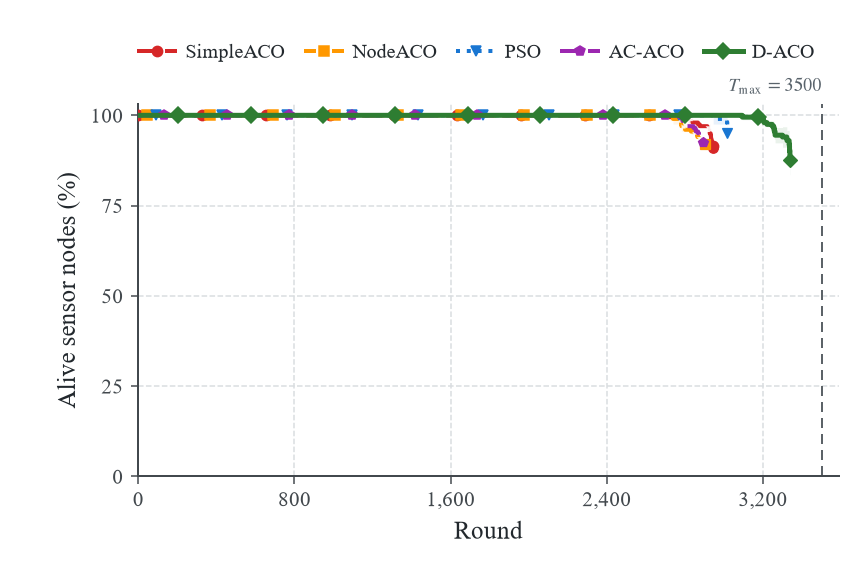

**500_500_500_100_uniform_cumulative** — Cumulative modeled energy demand versus round: 500 × 500 × 500 m; 100 sensors; uniform deployment. Curves are means over fixed per-algorithm cohorts, ending at the shortest selected run. Pale envelopes show sample SD where enabled and n > 1. Filled endpoints indicate the end of the displayed cohort window, not node death or a known termination cause. The dashed reference marks the configured simulation limit T_max = 3,500 rounds; curves are not extended to that limit. 

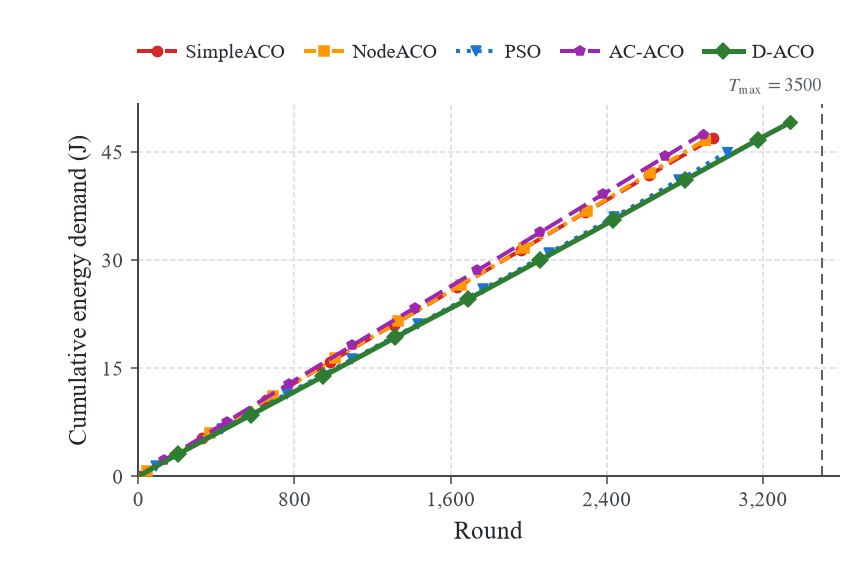

**500_500_500_100_uniform_round** — Modeled round-energy demand, 100-round block means: 500 × 500 × 500 m; 100 sensors; uniform deployment. Curves are means over fixed per-algorithm cohorts, ending at the shortest selected run. Pale envelopes show sample SD where enabled and n > 1. Filled endpoints indicate the end of the displayed cohort window, not node death or a known termination cause. The dashed reference marks the configured simulation limit T_max = 3,500 rounds; curves are not extended to that limit. 

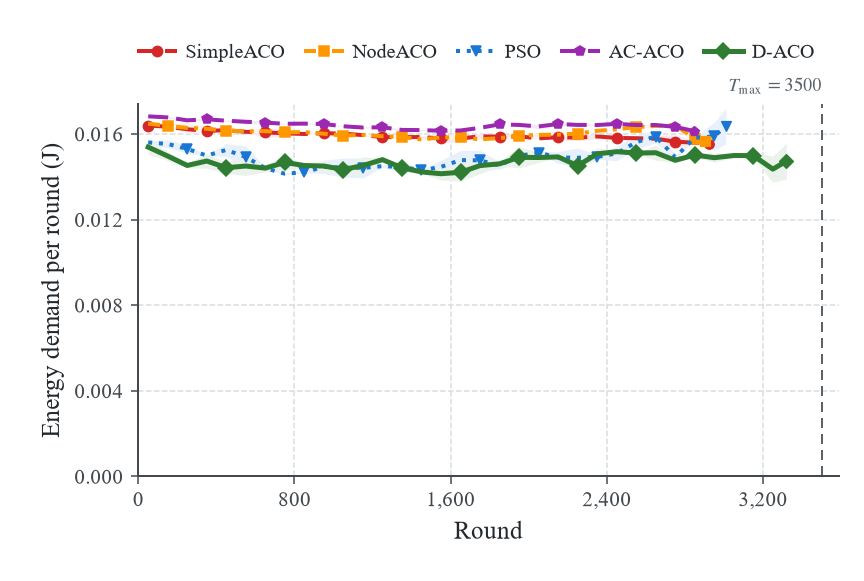

**500_500_500_100_uniform_alive_detail** — Survival detail: 500 × 500 × 500 m; 100 sensors; uniform deployment. The y-axis starts at 80%, rather than zero; compare the full-scale version for context. Fixed per-algorithm cohorts, mean and optional sample SD. The dashed reference marks the configured simulation limit T_max = 3,500 rounds; curves are not extended to that limit. 

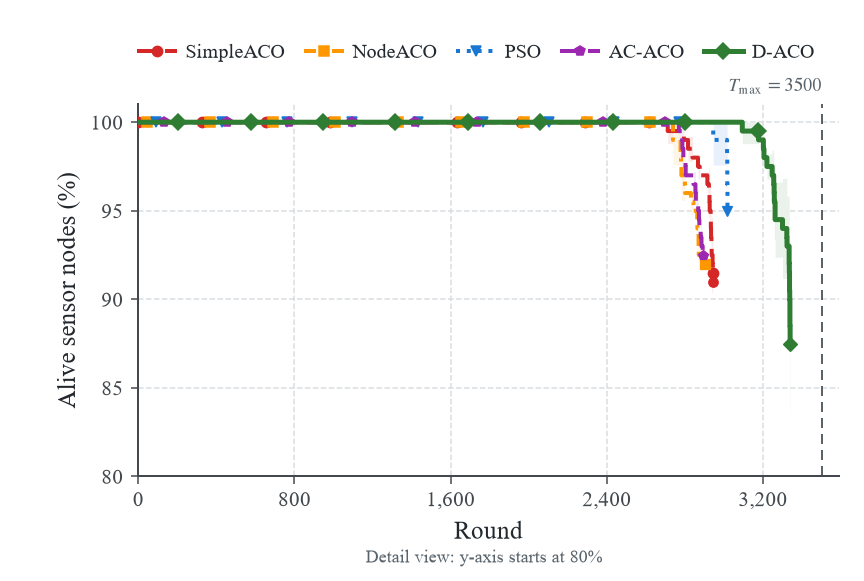

In [6]:
def curve_matrix(cohort, algo, kind):
    series = []
    for run in cohort:
        h = run["history"]
        if run["algo"] != algo or h.empty:
            continue
        if kind == "alive":
            y = h["alive_nodes"].to_numpy(dtype=float) / run["sensor_count"] * 100
        elif kind == "cumulative":
            y = h["round_energy"].to_numpy(dtype=float).cumsum()
        elif kind in ["runtime", "compute_cumulative"]:
            # A missing timing sample is not zero; omit incomplete timing trajectories.
            if "time" not in h or not h["time"].notna().all():
                continue
            y = h["time"].to_numpy(dtype=float)
            y = y.cumsum() if kind == "compute_cumulative" else y * 1000
        else:
            y = h["round_energy"].to_numpy(dtype=float)
        s = pd.Series(y, index=h["paper_round"].to_numpy())
        if kind in ["alive", "cumulative", "compute_cumulative"]:
            s.loc[0] = 100.0 if kind == "alive" else 0.0
            s = s.sort_index()
        series.append(s)
    if not series:
        return pd.DataFrame()
    # Keep a fixed cohort at every displayed round; never average a shrinking tail.
    matrix = pd.concat(series, axis=1).dropna(how="any")
    if kind in ["round", "runtime"]:
        groups = (matrix.index.to_numpy()-1) // AVG_WINDOW
        means = matrix.groupby(groups).mean()
        means.index = pd.Series(matrix.index.to_numpy()).groupby(groups).mean().to_numpy()
        matrix = means
    return matrix


def draw_curves(ax, cohort, kind, uncertainty=SHOW_SD):
    drawn = []
    for algo in algo_order(r["algo"] for r in cohort):
        mat = curve_matrix(cohort, algo, kind)
        if mat.empty:
            continue
        x, mean = mat.index.to_numpy(), mat.mean(axis=1).to_numpy()
        style = line_style(algo)
        offset = ALGORITHMS.index(algo) * max(1, len(x)//65)
        markevery = (min(offset, len(x)-1), max(1, len(x)//9))
        ax.plot(x, mean, markevery=markevery, drawstyle="steps-post" if kind == "alive" else "default",
                label=algo, **style)
        # Opaque, pale SD envelope is also safe in EPS (no transparency flattening).
        if uncertainty and mat.shape[1] > 1 and kind not in ["runtime", "compute_cumulative"]:
            sd = mat.std(axis=1, ddof=1).to_numpy()
            low = np.maximum(0, mean-sd)
            high = np.minimum(100, mean+sd) if kind == "alive" else mean+sd
            ax.fill_between(x, low, high, step="post" if kind == "alive" else None,
                            color=pale(algo), linewidth=0, zorder=1)
        ax.plot(x[-1], mean[-1], marker=MARKERS[algo], color=color(algo), markersize=3.8,
                markerfacecolor=color(algo), markeredgewidth=0.5, zorder=6)
        drawn.append(algo)
    if not drawn:
        ax.text(0.5, 0.5, "No completed rounds", transform=ax.transAxes, ha="center", color="#59636B")
    ax.set_xlabel("Round")
    ax.set_xlim(left=0)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=5, integer=True))
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    return drawn


for env in selected_envs:
    cohort = RUNS_BY_ENV[env]
    scenario = environment_label(env)
    algos = algo_order(r["algo"] for r in cohort if not r["history"].empty)
    for kind in ["alive", "cumulative", "round"]:
        fig, ax = canvas()
        drawn = draw_curves(ax, cohort, kind)
        legend_above(fig, drawn)
        if kind == "alive":
            ax.set_ylabel("Alive sensor nodes (%)")
            ax.set_ylim(0, 103)
            ax.set_yticks([0, 25, 50, 75, 100])
            label = "Alive sensor nodes versus round"
        elif kind == "cumulative":
            ax.set_ylabel(f"Cumulative energy demand ({ENERGY_UNIT})")
            ax.set_ylim(bottom=0)
            label = "Cumulative modeled energy demand versus round"
        else:
            ax.set_ylabel(f"Energy demand per round ({ENERGY_UNIT})")
            ax.set_ylim(bottom=0)
            label = f"Modeled round-energy demand, {AVG_WINDOW}-round block means"
        horizon_line(ax, horizon_for(env))
        finish(fig, f"{env}_{kind}", f"{label}: {scenario}. Curves are means over fixed per-algorithm cohorts, "
               "ending at the shortest selected run. Pale envelopes show sample SD where enabled and n > 1. "
               "Filled endpoints indicate the end of the displayed cohort window, not node death or a known termination cause. " + horizon_caption(env),
               f"{label} for the compared algorithms, distinguished by color, marker, and line style.")

    fig, ax = canvas()
    drawn = draw_curves(ax, cohort, "alive")
    legend_above(fig, drawn)
    floors = [curve_matrix(cohort, a, "alive").min().min() for a in drawn]
    floor = max(0, 5 * np.floor((min(floors, default=0)-2) / 5))
    ax.set_ylim(floor, 101)
    ax.set_ylabel("Alive sensor nodes (%)")
    horizon_line(ax, horizon_for(env))
    finish(fig, f"{env}_alive_detail", f"Survival detail: {scenario}. The y-axis starts at {floor:g}%, "
           "rather than zero; compare the full-scale version for context. Fixed per-algorithm cohorts, mean and optional sample SD. " + horizon_caption(env),
           "A restricted-y-axis view of the alive-node curves showing differences near the initial node count.",
           f"Detail view: y-axis starts at {floor:g}%")


## 6. FND and simulation endpoint versus node count

Each figure fixes the deployment volume and distribution. FND lines connect cohort means **only where every selected run in that node-count group records FND**; open upward triangles mark endpoints without FND. Endpoint curves use all completed-service counts, with squares identifying runs at the configured horizon. Both views show `T_max` as a horizontal reference when the group has one common known horizon. Different horizons within a sweep require separate groups/filters for a fair comparison. Historical data may have only one file per group.


**500_500_500_clustered_fnd_vs_nodes** — Fnd versus initial node count in a fixed 500 × 500 × 500 m clustered deployment. FND means/SD use fully observed event groups; service duration counts completed rounds for all files. Upward triangles denote unobserved FND; squares denote the configured horizon was reached; these markers are slightly offset horizontally. A dashed horizontal reference marks T_max when a common horizon is specified. Increasing N also increases density.

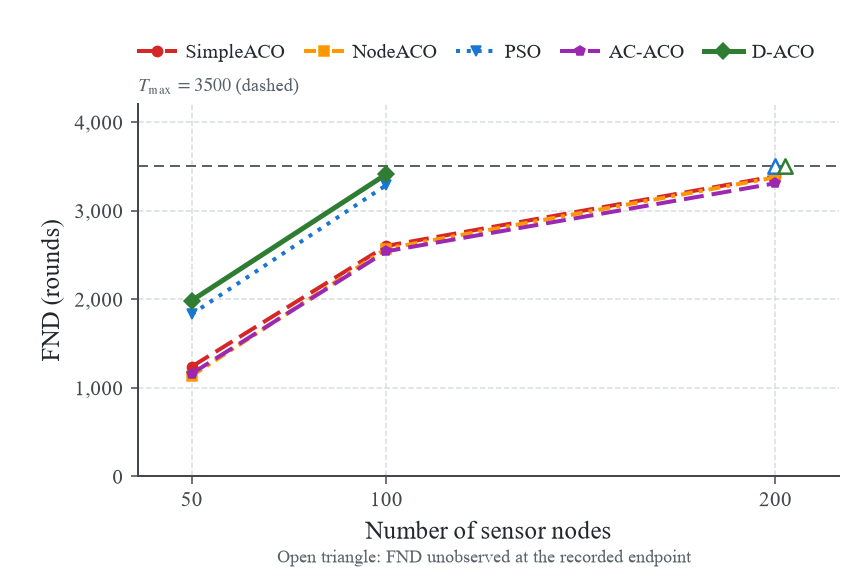

**500_500_500_clustered_service_vs_nodes** — Service versus initial node count in a fixed 500 × 500 × 500 m clustered deployment. FND means/SD use fully observed event groups; service duration counts completed rounds for all files. Upward triangles denote unobserved FND; squares denote the configured horizon was reached; these markers are slightly offset horizontally. A dashed horizontal reference marks T_max when a common horizon is specified. Increasing N also increases density.

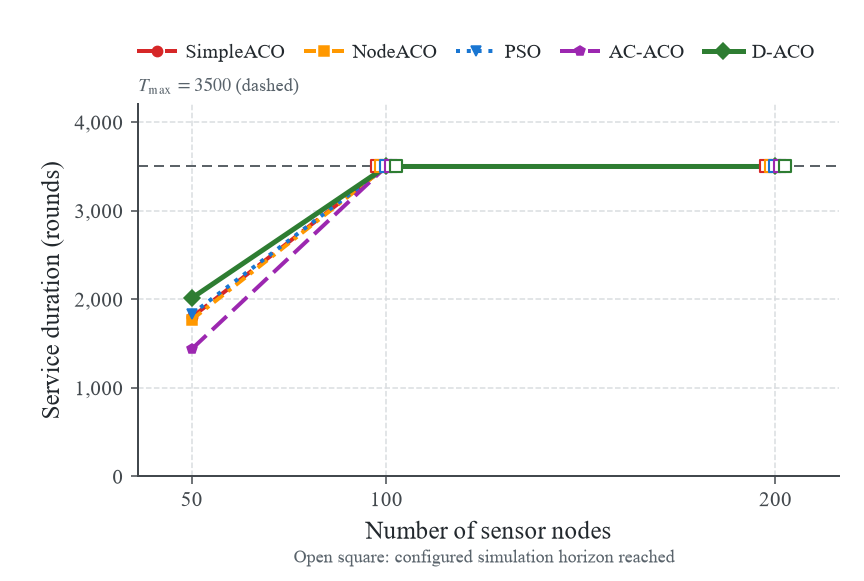

In [7]:
available_groups = sorted({r["group"] for r in runs})
chosen_groups = available_groups if SWEEP_GROUPS is None else SWEEP_GROUPS


def draw_node_sweep(selected, metric):
    fig, ax = canvas()
    node_counts = sorted(selected["sensor_count"].unique())
    algos = algo_order(selected["algo"])
    for ai, algo in enumerate(algos):
        means, sds = [], []
        for n in node_counts:
            g = selected.loc[(selected["algo"] == algo) & (selected["sensor_count"] == n)]
            valid = g if metric == "completed_rounds" else g.loc[~g["empty"]]
            vals = valid[metric].dropna().to_numpy(dtype=float)
            complete = len(g) > 0 and len(vals) == len(g)
            means.append(float(vals.mean()) if complete else np.nan)
            sds.append(float(vals.std(ddof=1)) if complete and len(vals) > 1 else np.nan)
            # Separate coincident endpoints slightly in x; the tick is the true node count.
            jitter = (ai - (len(algos)-1)/2) * min(np.diff(node_counts), default=50) * 0.025
            ends = valid.loc[valid[metric].isna(), "endpoint"].dropna().to_numpy(dtype=float)
            if len(ends) and metric == "FND":
                ax.scatter(np.full(len(ends), n+jitter), ends, marker="^", s=33,
                           facecolors="white", edgecolors=color(algo), linewidths=1, zorder=6)
            if not complete and len(vals):
                ax.scatter(np.full(len(vals), n+jitter), vals, marker=MARKERS[algo], s=19,
                           color=color(algo), zorder=5)
            if metric == "completed_rounds":
                capped = valid.loc[valid["endpoint_status"].eq("at configured horizon"), metric]
                if len(capped):
                    ax.scatter(np.full(len(capped), n+jitter), capped, marker="s", s=27,
                               facecolors="white", edgecolors=color(algo), linewidths=0.85, zorder=6)
        ax.plot(node_counts, means, **line_style(algo))
        if np.isfinite(sds).any():
            ax.errorbar(node_counts, means, yerr=sds, fmt="none", color=color(algo),
                        elinewidth=0.8, capsize=2.5, zorder=4)
    legend_above(fig, algos)
    ax.set_xlabel("Number of sensor nodes")
    ax.set_ylabel("Service duration (rounds)" if metric == "completed_rounds" else "FND (rounds)")
    ax.set_xticks(node_counts)
    ax.margins(x=0.09, y=0.12)
    ax.set_ylim(bottom=0)
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    horizons = {horizon_for(env) for env in selected["environment"].unique()}
    if len(horizons) == 1 and None not in horizons:
        horizon_line(ax, next(iter(horizons)), axis="y")
    return fig, ax


for group_key in chosen_groups:
    selected = summary.loc[summary["group"].map(lambda v: v == tuple(group_key))]
    if selected.empty:
        print(f"No node-count data for {group_key}; skipped.")
        continue
    w, h, d, distribution = group_key
    for metric, suffix in [("FND", "fnd"), ("completed_rounds", "service")]:
        fig, ax = draw_node_sweep(selected, metric)
        finish(fig, f"{w}_{h}_{d}_{distribution}_{suffix}_vs_nodes",
               f"{suffix.title()} versus initial node count in a fixed {w} × {h} × {d} m {distribution} deployment. "
               "FND means/SD use fully observed event groups; service duration counts completed rounds for all files. "
               "Upward triangles denote unobserved FND; squares denote the configured horizon was reached; these markers are slightly offset horizontally. "
               "A dashed horizontal reference marks T_max when a common horizon is specified. Increasing N also increases density.",
               f"{suffix.title()} versus node count, distinguishing observations and configured-horizon limits.",
               "Open triangle: FND unobserved at the recorded endpoint" if metric == "FND" else
               "Open square: configured simulation horizon reached")


## 7. Computation runtime — four views

1. **Mean runtime per round by algorithm:** mean over the same first `RUNTIME_WINDOW` rounds in every eligible file; sample SD across files and individual-file dots. No shorter-run average is substituted for that window.
2. **Runtime per round versus simulation round:** non-overlapping block means, logarithmic y-axis by default to retain large timing spikes without compressing the normal operating range. This is elapsed computation time, not network transmission delay.
3. **Cumulative recorded computation time versus round:** sum the raw timers within each file before averaging. Longer service durations and timing spikes both increase the total; this is not a matched-work speed ranking.
4. **Runtime per round versus node count:** use the same fixed K-round window and fixed deployment volume/distribution. Do not draw a mean for an incomplete K-round group.

`T_max` is a vertical line only in round-indexed runtime timelines, not in charts whose axes are milliseconds and algorithm/node count. The timing audit table exposes the largest recorded round. Hardware load, concurrent workers, and historical environment differences are uncontrolled; these are descriptive timings, not a controlled speed benchmark. Initialization is included in all K-round summaries.


,file,completed_rounds,runtime_K_ms,recorded_compute_s,max_round_time_s
0,500_500_500_100_uniform_2026101400_89_D-ACO.csv,3339,88.304110,1955.388957,1616.427164
1,500_500_500_100_uniform_2026101400_89_AC-ACO.csv,2897,153.547576,469.203514,1.186183
2,500_500_500_100_uniform_2026101400_89_PSO.csv,3018,70.156756,275.654263,0.877071
3,500_500_500_100_uniform_2026101400_68_AC-ACO.csv,2891,122.090903,351.036651,0.844420
4,500_500_500_100_uniform_2026101400_68_PSO.csv,3107,94.217183,317.540559,0.742259
5,500_500_500_100_uniform_2026101400_89_NodeACO.csv,2905,117.725152,333.172052,0.697639
6,500_500_500_100_uniform_2026101400_68_D-ACO.csv,3350,108.987121,368.772455,0.686290
7,500_500_500_100_uniform_2026101400_68_NodeACO.csv,2911,82.233186,271.528702,0.528234
8,500_500_500_100_uniform_2026101400_89_SimpleACO.csv,2944,110.914658,317.697195,0.470344
9,500_500_500_100_uniform_2026101400_68_SimpleACO.csv,2954,88.653849,256.134400,0.439025


**500_500_500_100_uniform_runtime_mean** — Mean computation time per round over the first 1,000 completed rounds: 500 × 500 × 500 m; 100 sensors; uniform deployment. Each file contributes its own K-round mean, including initialization. Bars: mean; whiskers: sample SD; dots: eligible files. Files without a complete timed K-round window are excluded and counted where applicable.

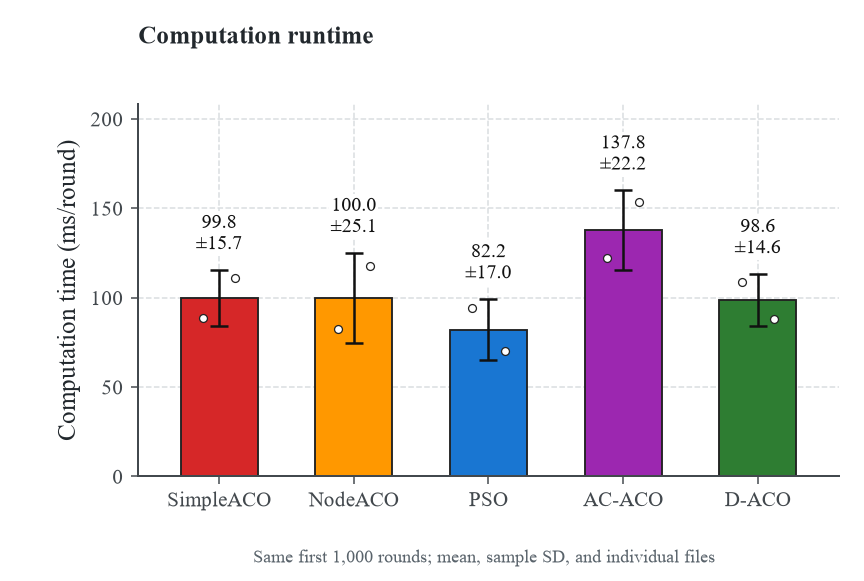

**500_500_500_100_uniform_runtime_by_round** — Computation runtime, 100-round block means: 500 × 500 × 500 m; 100 sensors; uniform deployment. Logarithmic y-axis; all valid positive block means, including spikes, are retained. Fixed per-algorithm cohorts end at their shortest selected timing history; SD bands are omitted for readability. Timers exclude unrecorded failed attempts and CSV output. The dashed reference marks the configured simulation limit T_max = 3,500 rounds; curves are not extended to that limit. 

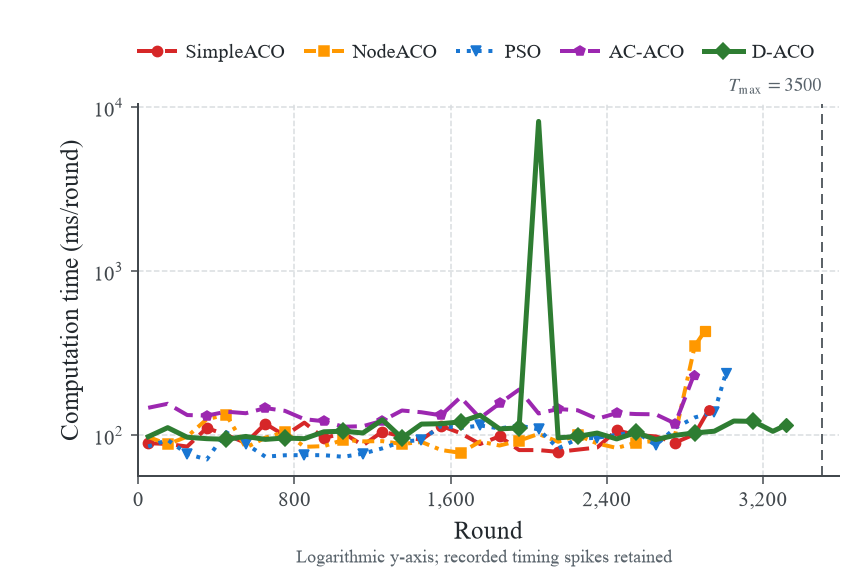

**500_500_500_100_uniform_runtime_cumulative** — Cumulative recorded computation time: 500 × 500 × 500 m; 100 sensors; uniform deployment. Raw completed-round timers are accumulated per file before averaging; timing spikes are retained. Fixed per-algorithm cohorts end at their shortest selected timing history; SD bands are omitted for readability. Timers exclude unrecorded failed attempts and CSV output. The dashed reference marks the configured simulation limit T_max = 3,500 rounds; curves are not extended to that limit. 

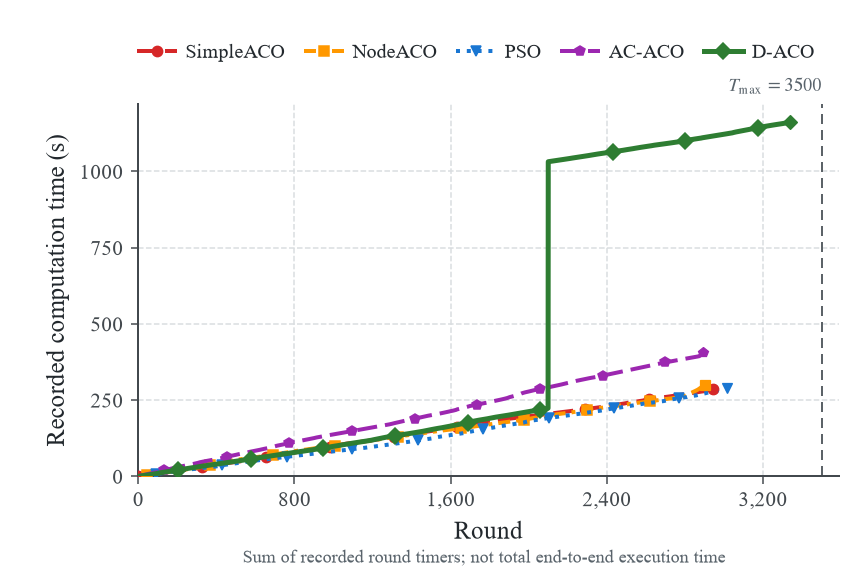

**500_500_500_clustered_runtime_vs_nodes** — Mean computation time per round over the same first 1,000 completed rounds, in 500 × 500 × 500 m clustered deployments. Includes initialization; error bars show sample SD across files when n > 1. Groups without complete K-round timing in every selected file remain gaps. Historical hardware/concurrency is uncontrolled.

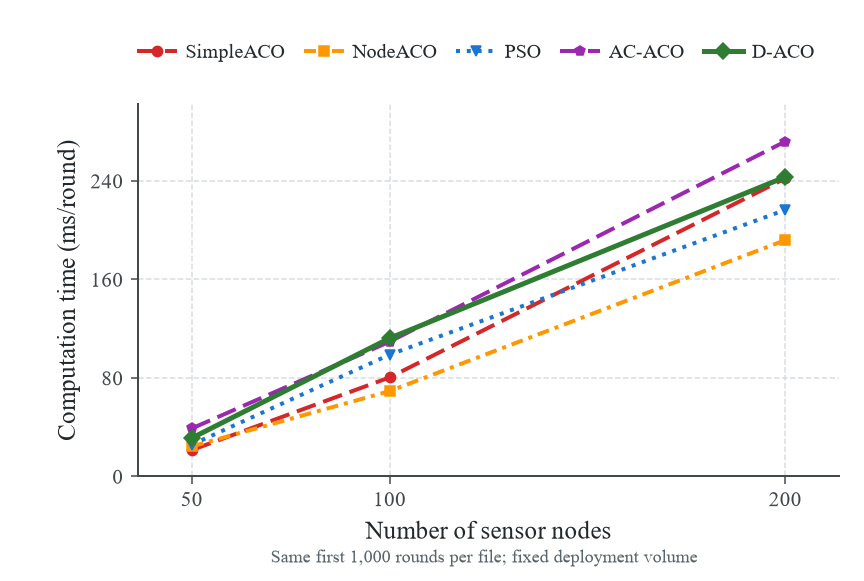

In [8]:
timing_scope = summary.loc[summary["environment"].isin(selected_envs)]
display(timing_scope[["file", "completed_rounds", "runtime_K_ms", "recorded_compute_s", "max_round_time_s"]]
        .sort_values("max_round_time_s", ascending=False).reset_index(drop=True))


def runtime_bar(ax, frame):
    algos = algo_order(frame["algo"])
    all_highs = []
    for x, algo in enumerate(algos):
        group = frame.loc[frame["algo"] == algo]
        vals = group["runtime_K_ms"].dropna().to_numpy(dtype=float)
        if not len(vals):
            ax.text(x, 0.08, "No K-round timing", transform=ax.get_xaxis_transform(),
                    ha="center", rotation=90, fontsize=7, color="#59636B")
            continue
        mean, sd = float(vals.mean()), float(vals.std(ddof=1)) if len(vals) > 1 else 0.0
        ax.bar(x, mean, width=0.57, color=color(algo), edgecolor="#222222", linewidth=0.75,
               hatch=HATCHES.get(algo, "") if MONOCHROME else None, zorder=2)
        if len(vals) > 1:
            ax.errorbar(x, mean, yerr=sd, fmt="none", color="#111111", capsize=3.5, elinewidth=1.0, zorder=4)
        offsets = np.linspace(-0.12, 0.12, len(vals)) if len(vals) > 1 else np.zeros(1)
        ax.scatter(x+offsets, vals, s=10, facecolors="white", edgecolors="#222222", linewidths=0.5, zorder=5)
        top = max(vals.max(), mean+sd)
        all_highs.append(top)
        label = statistic_label(vals, decimals=1) + (f"\n(n={len(vals)}/{len(group)})" if len(vals) < len(group) else "")
        ax.annotate(label, (x, top), xytext=(0, 6), textcoords="offset points", ha="center", va="bottom", fontsize=8, color="#111111",
                    bbox=dict(facecolor="white", edgecolor="none", pad=0.6))
    ax.set_xticks(range(len(algos)), algos)
    ax.set_ylabel("Computation time (ms/round)")
    ax.set_ylim(0, max(1, max(all_highs, default=1))*1.30)
    ax.set_xlim(-0.6, len(algos)-0.4)


for env in selected_envs:
    frame, cohort = summary.loc[summary["environment"] == env], RUNS_BY_ENV[env]
    fig, ax = canvas()
    runtime_bar(ax, frame)
    fig.text(0.16, 0.925, "Computation runtime", fontsize=10, fontweight="bold")
    finish(fig, f"{env}_runtime_mean", f"Mean computation time per round over the first {RUNTIME_WINDOW:,} completed rounds: "
           f"{environment_label(env)}. Each file contributes its own K-round mean, including initialization. "
           "Bars: mean; whiskers: sample SD; dots: eligible files. Files without a complete timed K-round window are excluded and counted where applicable.",
           "Algorithm runtime comparison over an identical number of completed service rounds.",
           f"Same first {RUNTIME_WINDOW:,} rounds; mean, sample SD, and individual files")

    for kind, suffix in [("runtime", "runtime_by_round"), ("compute_cumulative", "runtime_cumulative")]:
        fig, ax = canvas()
        drawn = draw_curves(ax, cohort, kind, uncertainty=False)
        legend_above(fig, drawn)
        if kind == "runtime":
            ax.set_ylabel("Computation time (ms/round)")
            if RUNTIME_LOG_SCALE and drawn:
                ax.set_yscale("log")
                ax.yaxis.set_minor_locator(mpl.ticker.NullLocator())
            else:
                ax.set_ylim(bottom=0)
            label = f"Computation runtime, {AVG_WINDOW}-round block means"
            detail = ("Logarithmic y-axis; all valid positive block means, including spikes, are retained. "
                      if RUNTIME_LOG_SCALE else "Linear y-axis; no timing outliers are removed. ")
            note = "Logarithmic y-axis; recorded timing spikes retained" if RUNTIME_LOG_SCALE else None
        else:
            ax.set_ylabel("Recorded computation time (s)")
            ax.set_ylim(bottom=0)
            label = "Cumulative recorded computation time"
            detail = "Raw completed-round timers are accumulated per file before averaging; timing spikes are retained. "
            note = "Sum of recorded round timers; not total end-to-end execution time"
        horizon_line(ax, horizon_for(env))
        finish(fig, f"{env}_{suffix}", f"{label}: {environment_label(env)}. " + detail +
               "Fixed per-algorithm cohorts end at their shortest selected timing history; SD bands are omitted for readability. "
               "Timers exclude unrecorded failed attempts and CSV output. " + horizon_caption(env),
               f"{label} versus round, with a dashed configured-horizon reference.", note)

for group_key in chosen_groups:
    selected = summary.loc[summary["group"].map(lambda v: v == tuple(group_key))]
    if selected.empty:
        continue
    fig, ax = canvas()
    counts = sorted(selected["sensor_count"].unique())
    algos = algo_order(selected["algo"])
    for algo in algos:
        means, sds = [], []
        for n in counts:
            g = selected.loc[(selected["algo"] == algo) & (selected["sensor_count"] == n)]
            vals = g["runtime_K_ms"].dropna().to_numpy(dtype=float)
            complete = len(g) > 0 and len(vals) == len(g)
            means.append(float(vals.mean()) if complete else np.nan)
            sds.append(float(vals.std(ddof=1)) if complete and len(vals) > 1 else np.nan)
        ax.plot(counts, means, **line_style(algo))
        if np.isfinite(sds).any():
            ax.errorbar(counts, means, yerr=sds, fmt="none", color=color(algo), capsize=2.5, elinewidth=0.8)
    legend_above(fig, algos)
    ax.set_xticks(counts)
    ax.set_xlabel("Number of sensor nodes")
    ax.set_ylabel("Computation time (ms/round)")
    ax.margins(x=0.09, y=0.12)
    ax.set_ylim(bottom=0)
    w, h, d, distribution = group_key
    finish(fig, f"{w}_{h}_{d}_{distribution}_runtime_vs_nodes",
           f"Mean computation time per round over the same first {RUNTIME_WINDOW:,} completed rounds, "
           f"in {w} × {h} × {d} m {distribution} deployments. Includes initialization; error bars show sample SD across files when n > 1. "
           "Groups without complete K-round timing in every selected file remain gaps. Historical hardware/concurrency is uncontrolled.",
           "Computation runtime per round versus sensor count over a fixed service window.",
           f"Same first {RUNTIME_WINDOW:,} rounds per file; fixed deployment volume")


## 8. Ranked sensor-energy profile

This retains the exploratory profile from `analyze.ipynb`. Each run is sorted independently before averaging by rank, so sensor ID need not denote the same location across maps. Totals are measured at each run's own endpoint; use this descriptively, not as evidence of equal-window energy balance. `T_max` is not drawn on this chart because neither axis measures simulation rounds. Missing or invalid sidecars are reported.


**500_500_500_100_uniform_sensor_energy_rank** — Ranked sensor-energy demand: 500 × 500 × 500 m; 100 sensors; uniform deployment. Each run is sorted before rank-wise averaging. Totals come from each run's own endpoint; this is not an equal-service-window balance comparison.

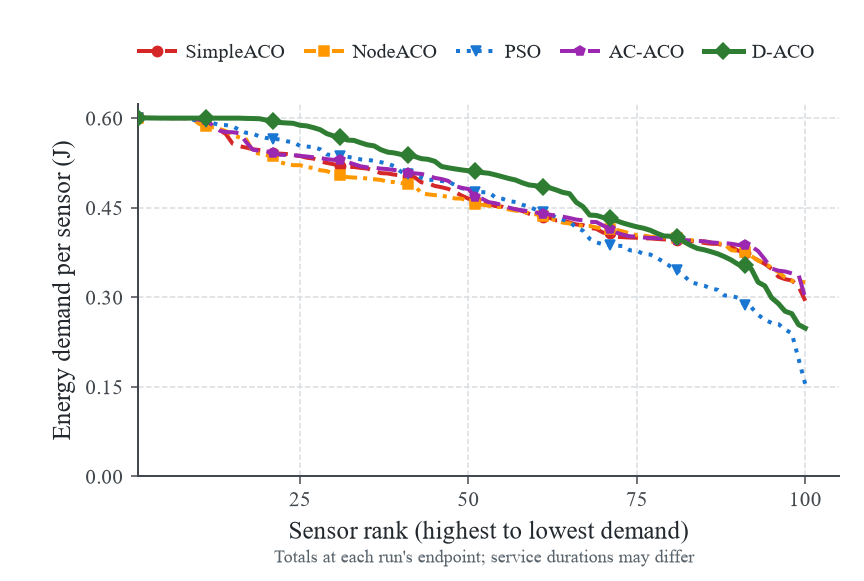

In [9]:
for env in selected_envs:
    frame = summary.loc[summary["environment"] == env]
    algos = algo_order(frame["algo"])
    fig, ax = canvas()
    drawn = []
    for algo in algos:
        profiles = []
        for run in RUNS_BY_ENV[env]:
            if run["algo"] != algo or run["history"].empty:
                continue
            path = run["path"].with_name(run["path"].stem + "_sensor-energy.csv")
            if not path.is_file():
                print(f"Missing sidecar: {path.name}")
                continue
            data = pd.read_csv(path)
            if not {"sensor", "total_energy"} <= set(data.columns) or len(data) != run["sensor_count"] or data["sensor"].duplicated().any():
                print(f"Invalid sidecar shape/IDs: {path.name}")
                continue
            vals = pd.to_numeric(data["total_energy"], errors="raise").to_numpy(dtype=float)
            if not np.isfinite(vals).all() or (vals < 0).any():
                raise ValueError(f"Invalid sensor energy values: {path.name}")
            profiles.append(np.sort(vals)[::-1])
        if profiles:
            mean = np.mean(profiles, axis=0)
            ax.plot(np.arange(1, len(mean)+1), mean, markevery=max(1, len(mean)//10), **line_style(algo))
            drawn.append(algo)
    if not drawn:
        ax.text(0.5, 0.5, "No valid sensor-energy sidecars", transform=ax.transAxes, ha="center")
    legend_above(fig, drawn)
    ax.set_xlabel("Sensor rank (highest to lowest demand)")
    ax.set_ylabel(f"Energy demand per sensor ({ENERGY_UNIT})")
    ax.set_ylim(bottom=0)
    ax.set_xlim(left=1)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=5, integer=True))
    finish(fig, f"{env}_sensor_energy_rank", f"Ranked sensor-energy demand: {environment_label(env)}. "
           "Each run is sorted before rank-wise averaging. Totals come from each run's own endpoint; this is not an equal-service-window balance comparison.",
           "Ranked per-sensor modeled energy-demand profiles, with no overlapping area fills.",
           "Totals at each run's endpoint; service durations may differ")


## 9. Save captions, provenance, and a visual contact sheet

The preview board is for selecting figures. Each independent PDF/PNG above retains the actual publication geometry. Suggested captions and `\Description` text are exported to JSON; scientific claims still need a controlled cohort. The manifest records file hashes and filters, but cannot recover missing historical map/configuration metadata.

**Future data needed:** per-node residual energy at common rounds for energy-variance graphs. This notebook intentionally does not invent residual trajectories or packet-delivery metrics from aggregate energy logs.


Rendered 14 figures. Exports: C:\Users\hgtfh\Code\uwsn\review_uwsn\output\figures\analyze2


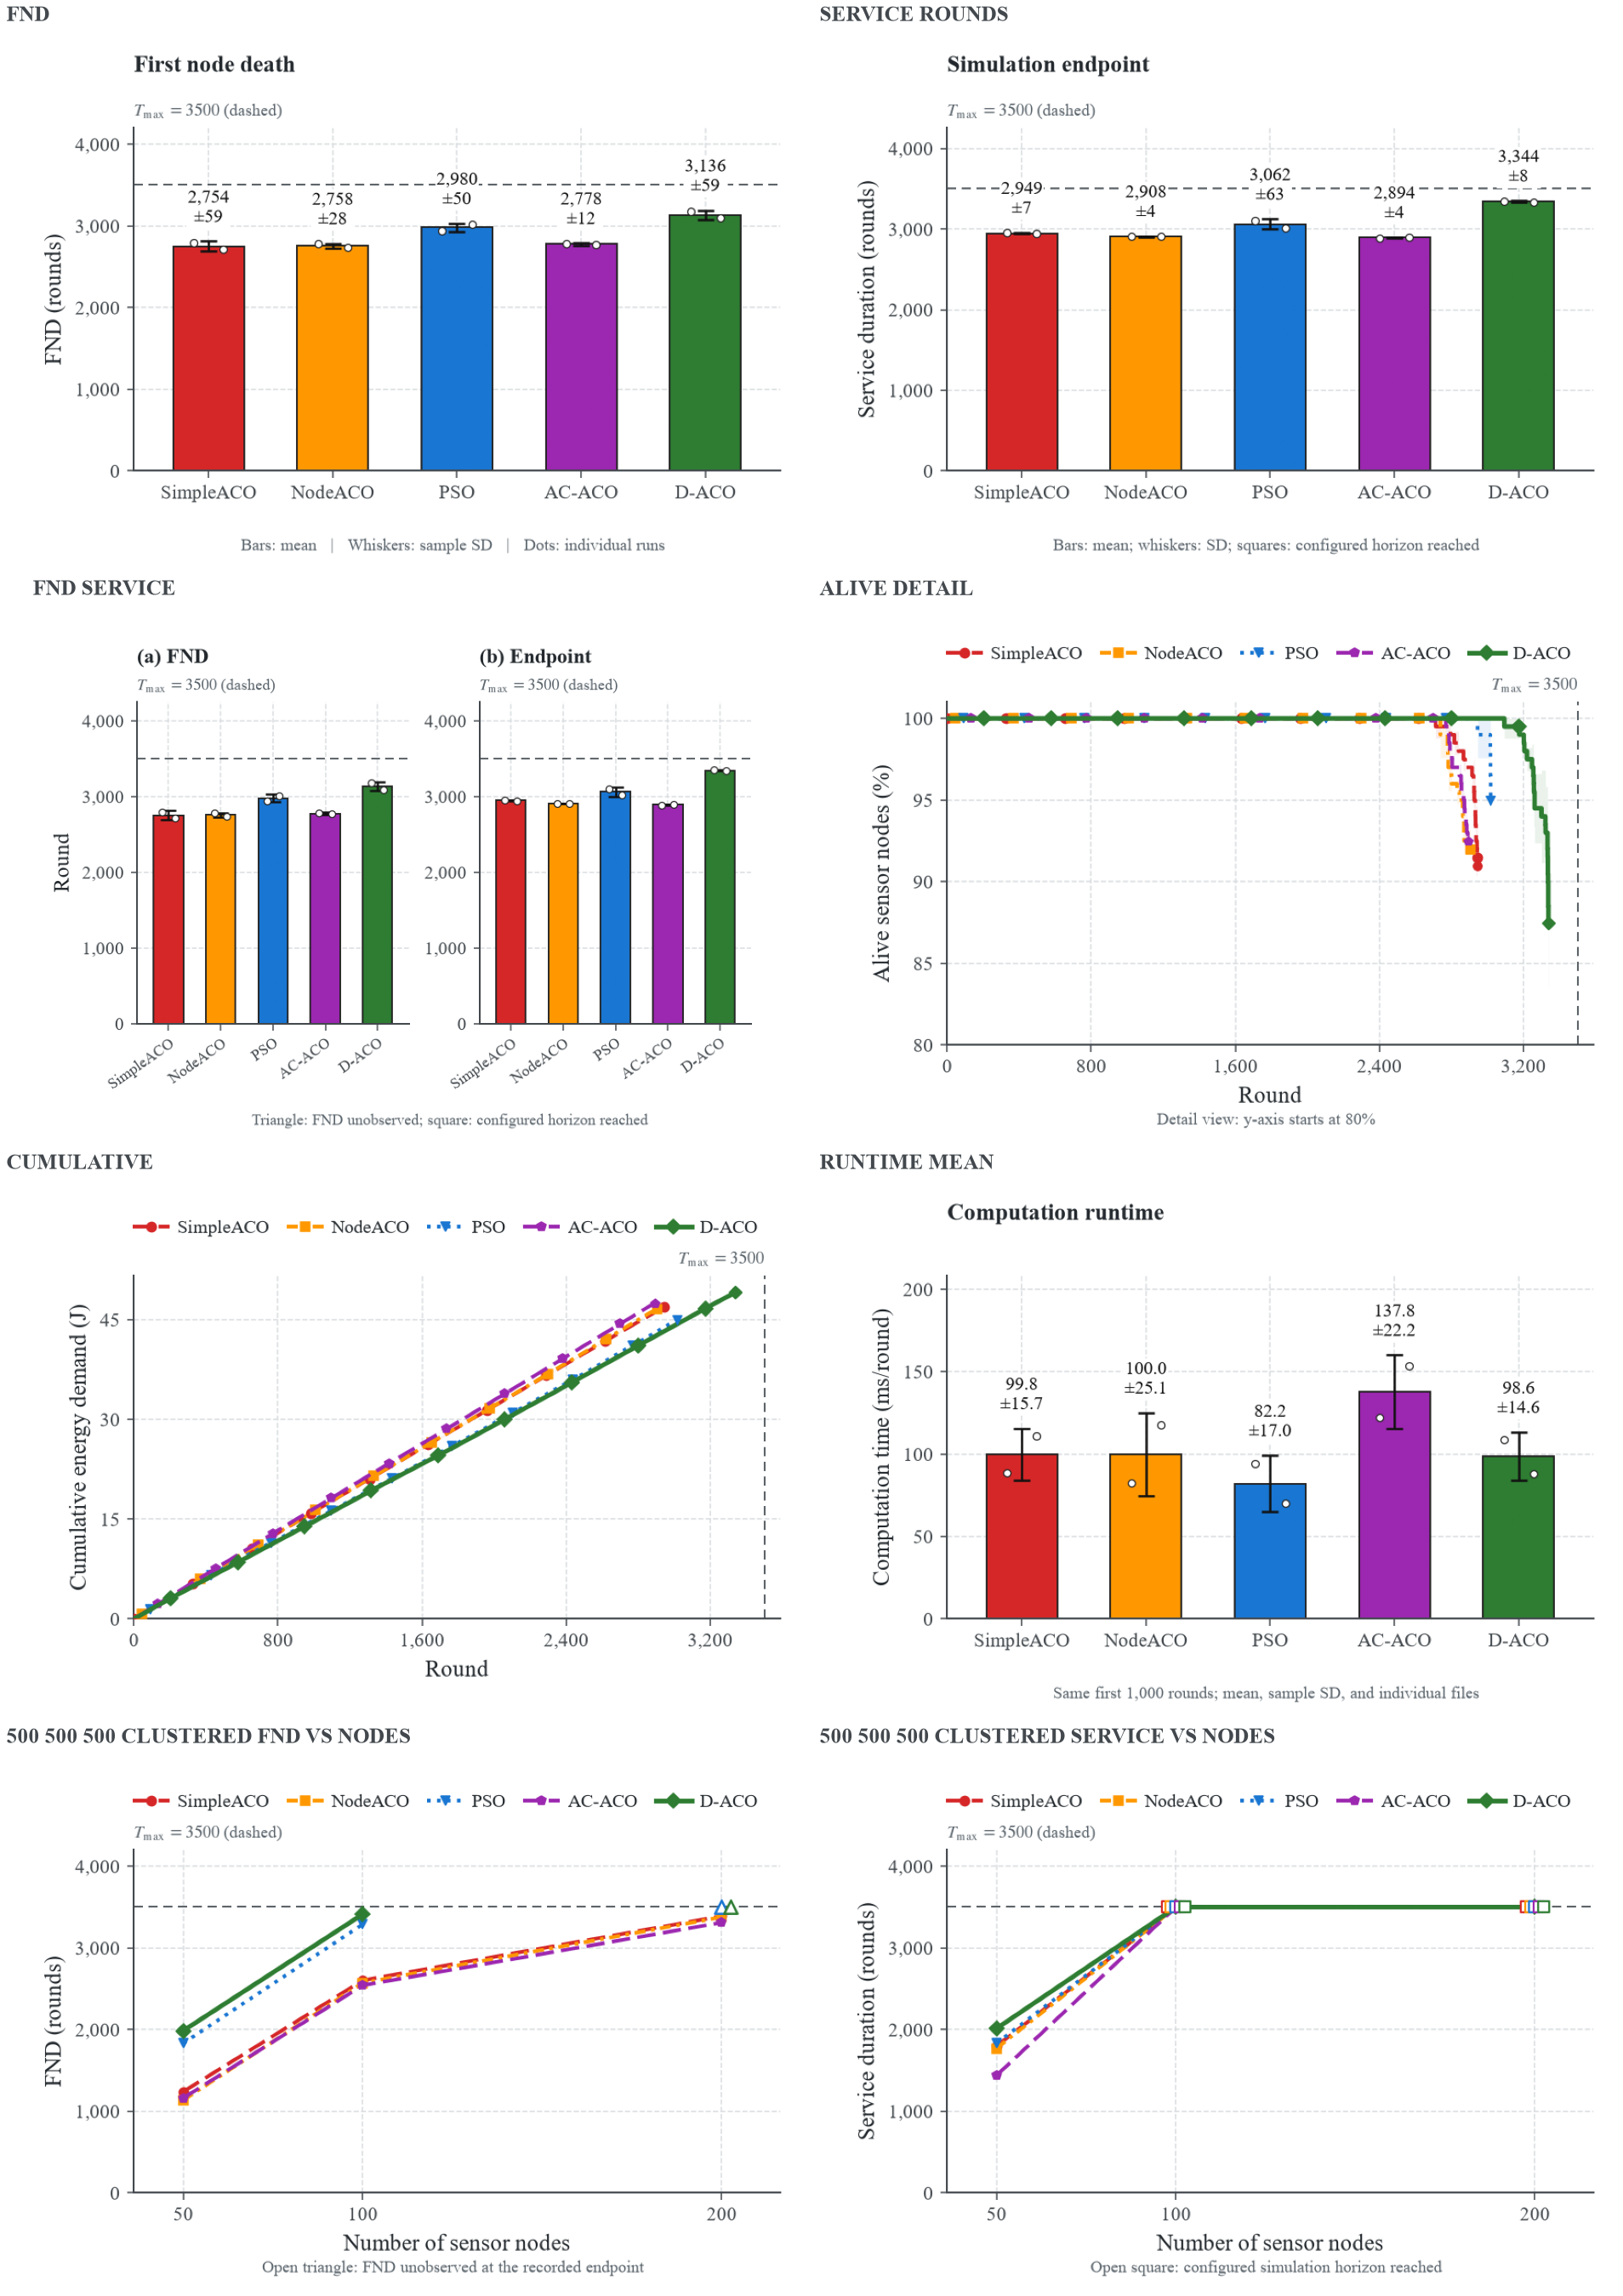

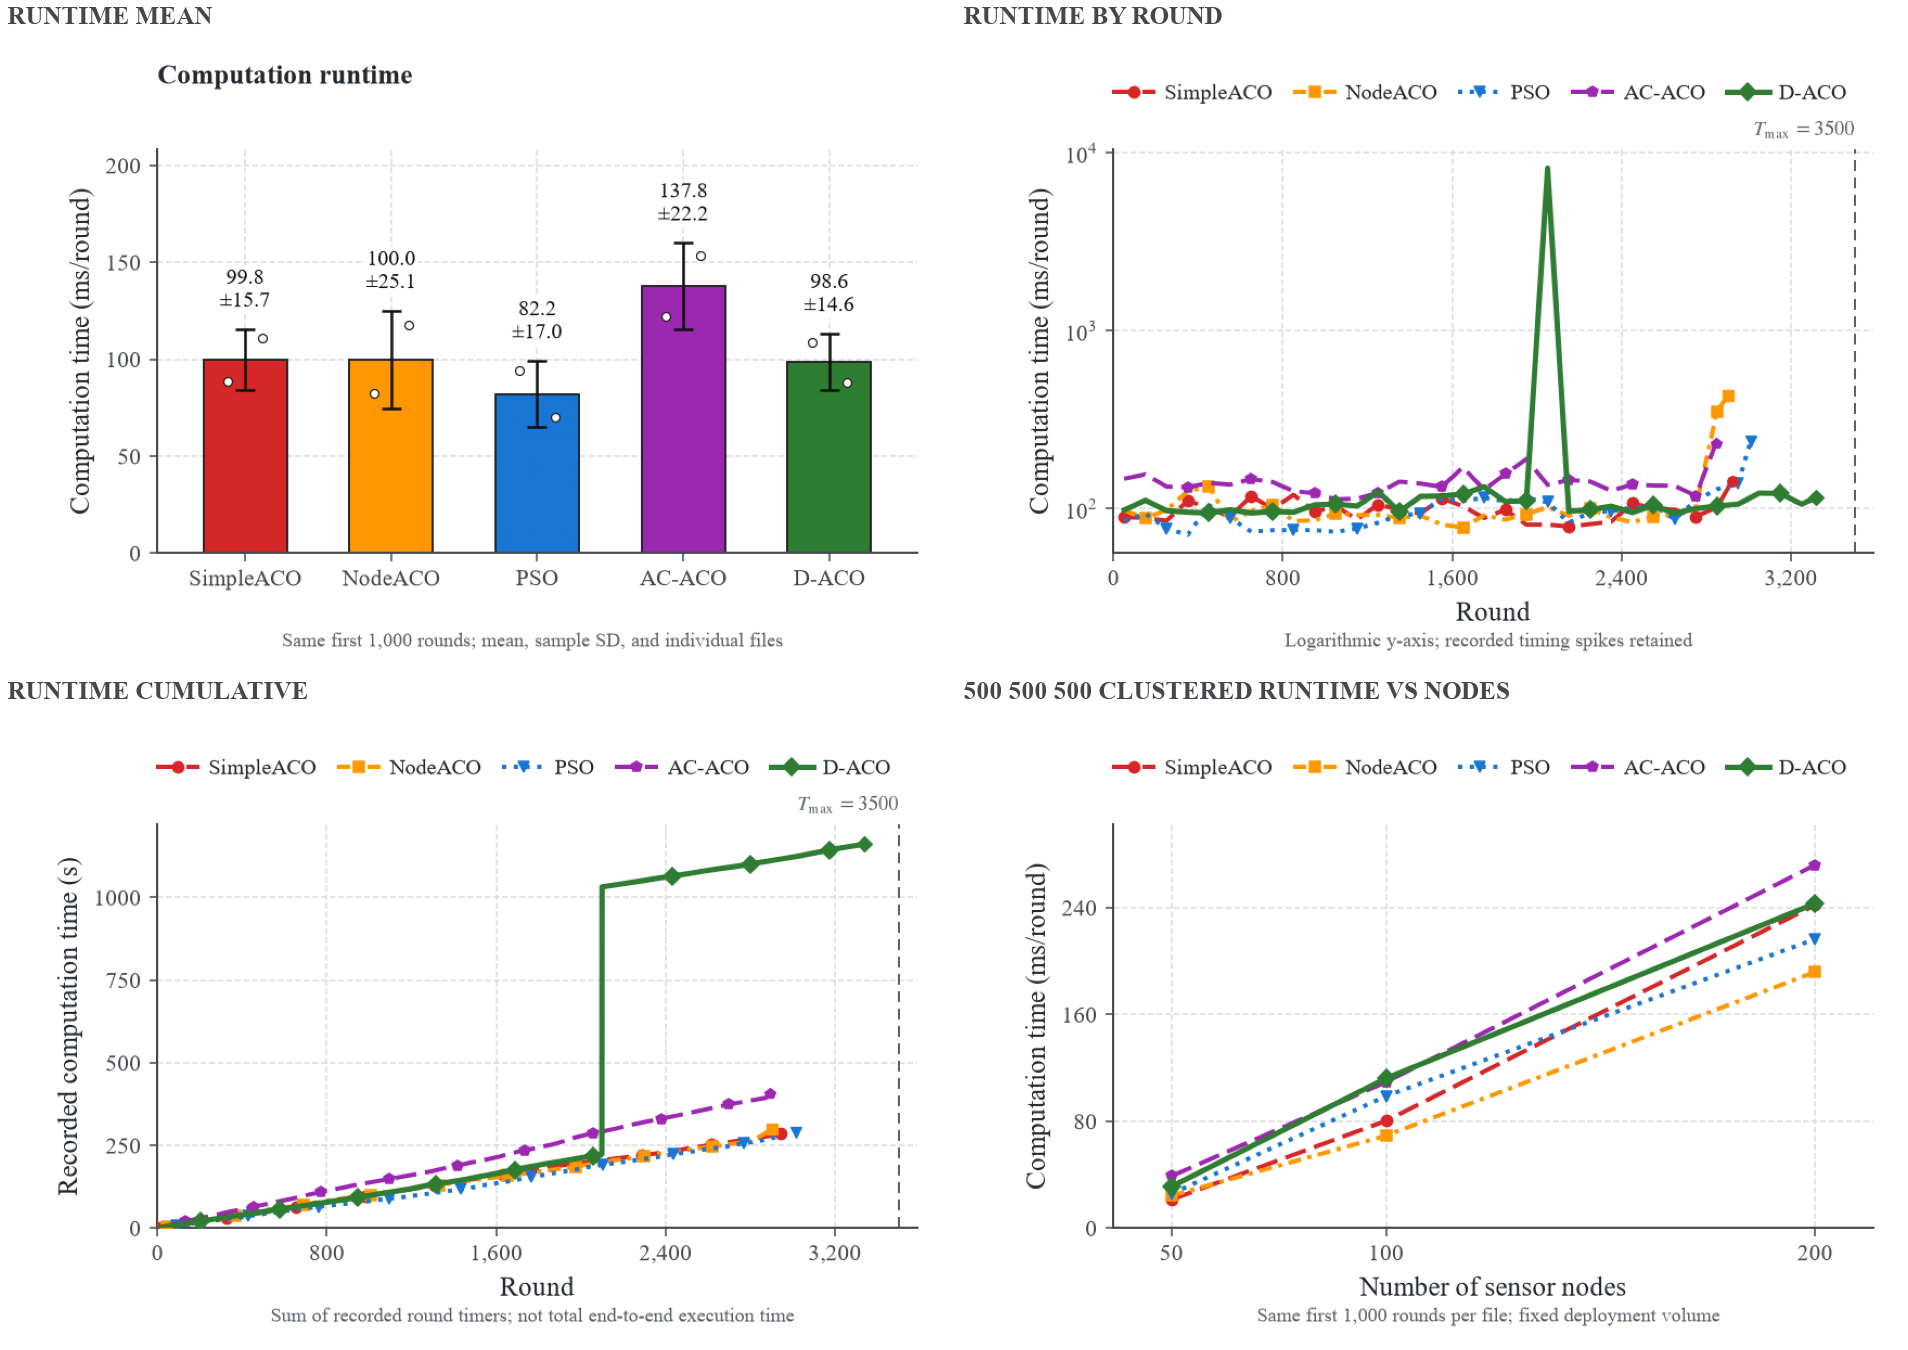

In [10]:
if EXPORT:
    selected_groups = {tuple(g) for g in chosen_groups}
    manifest_runs = [r for r in runs if r["environment"] in selected_envs or r["group"] in selected_groups]
    manifest = {
        "purpose": "Historical CSV figure-design preview; not a provenance-verified experimental cohort",
        "filters": dict(start=START_DATETIME, end=END_DATETIME, seeds=SEEDS,
                        algorithms=ALGORITHMS, environments=ENVIRONMENTS, sweep_groups=SWEEP_GROUPS,
                        configured_T_max=T_MAX, horizon_overrides=T_MAX_BY_ENV, runtime_window=RUNTIME_WINDOW),
        "style": dict(width_mm=FIG_WIDTH_MM, height_mm=FIG_HEIGHT_MM, font=FONT_FAMILY,
                      font_pt=FONT_PT, palette=PALETTE, monochrome=MONOCHROME,
                      show_sample_sd=SHOW_SD, average_window=AVG_WINDOW),
        "runs": [],
    }
    for run in manifest_runs:
        path = run["path"]
        item = dict(file=path.name, sha256=hashlib.sha256(path.read_bytes()).hexdigest(),
                    environment=run["environment"], algorithm=run["algo"], seed=run["seed"],
                    timestamp=run["timestamp"], completed_rounds=len(run["history"]))
        item["configured_T_max"] = horizon_for(run["environment"])
        metadata_path = path.with_suffix(".meta.json")
        if metadata_path.is_file():
            item["run_metadata"] = run["metadata"]
            item["run_metadata_sha256"] = hashlib.sha256(metadata_path.read_bytes()).hexdigest()
        sidecar = path.with_name(path.stem + "_sensor-energy.csv")
        if sidecar.is_file():
            item["sensor_energy_sha256"] = hashlib.sha256(sidecar.read_bytes()).hexdigest()
        manifest["runs"].append(item)
    (OUTPUT_DIR / "figure_captions.json").write_text(json.dumps(FIGURE_METADATA, indent=2, ensure_ascii=False), encoding="utf-8")
    (OUTPUT_DIR / "cohort_manifest.json").write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8")
    summary.loc[summary["file"].isin([r["path"].name for r in manifest_runs])].drop(columns="group").to_csv(
        OUTPUT_DIR / "run_metrics.csv", index=False)

# Compose from the actual rendered figures, not a separately drawn mock-up.
board_keys = []
if selected_envs:
    env = selected_envs[0]
    board_keys += [f"{env}_{suffix}" for suffix in ["fnd", "service_rounds", "fnd_service", "alive_detail", "cumulative", "runtime_mean"]]
board_keys += [k for k in FIGURES if k.endswith("_fnd_vs_nodes")][:1]
board_keys += [k for k in FIGURES if k.endswith("_service_vs_nodes")][:1]


def contact_sheet(keys, filename):
    keys = [k for k in keys if k in FIGURES]
    if not keys:
        return
    board, axes = plt.subplots(int(np.ceil(len(keys)/2)), 2, figsize=(10.6, 3.75*np.ceil(len(keys)/2)),
                               squeeze=False, layout="constrained")
    for ax in axes.flat:
        ax.axis("off")
    for ax, key in zip(axes.flat, keys):
        source = FIGURES[key]
        preview = BytesIO()
        source.savefig(preview, format="png", dpi=PREVIEW_DPI)
        preview.seek(0)
        ax.imshow(plt.imread(preview, format="png"))
        label = key.removeprefix(selected_envs[0] + "_").replace("_", " ") if selected_envs else key
        ax.set_title(label.upper(), loc="left", fontsize=10, fontweight="bold", color="#42484D", pad=5)
    if EXPORT:
        board.savefig(OUTPUT_DIR / filename, dpi=160)
    display(board)
    plt.close(board)


contact_sheet(board_keys, "design_overview.png")
runtime_keys = ([f"{selected_envs[0]}_{suffix}" for suffix in
                 ["runtime_mean", "runtime_by_round", "runtime_cumulative"]] if selected_envs else [])
runtime_keys += [k for k in FIGURES if k.endswith("_runtime_vs_nodes")][:1]
contact_sheet(runtime_keys, "runtime_overview.png")

print(f"Rendered {len(FIGURES)} figures. Exports: {OUTPUT_DIR}" if EXPORT else f"Rendered {len(FIGURES)} figures; export disabled.")
